# EDA & Data Cleaning — Three Datasets
**Order:** Loan → Adult Census → Hotel Booking

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

LOAN_PATH = Path("loan-train (1).csv")
ADULT_PATH = Path("adult (1).csv")
HOTEL_PATH = Path("hotel_booking (1).csv")
print("Loan file:", LOAN_PATH.exists(), "| Adult file:", ADULT_PATH.exists(), "| Hotel file:", HOTEL_PATH.exists())


Loan file: True | Adult file: True | Hotel file: True


## Reusable EDA Functions
Inspect data, profile every column, plot distributions, and check missing values.

In [7]:
def basic_report(df, dataset_name):
    print("=" * 90)
    print(f"{dataset_name} — BASIC INFORMATION")
    print("=" * 90)
    print("Shape:", df.shape)
    print("\\nData types:")
    display(df.dtypes.to_frame("dtype"))
    print("\\nFirst five rows:")
    display(df.head())
    print("\\nDuplicate rows:", df.duplicated().sum())
    print("\\nMissing values by column:")
    missing = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2)
    }).sort_values("missing_percent", ascending=False)
    display(missing)
    print("\\nNumeric descriptive statistics:")
    display(df.describe(include=[np.number]).T)
    print("\\nCategorical descriptive statistics:")
    display(df.describe(include=["object", "category"]).T)


def column_profile(df, dataset_name):
    print(f"\\n{dataset_name} — COLUMN-BY-COLUMN PROFILE")
    for col in df.columns:
        s = df[col]
        print("\\n" + "-" * 80)
        print(f"Column: {col} | dtype: {s.dtype} | missing: {s.isna().sum()} ({s.isna().mean()*100:.2f}%)")
        print("Unique values:", s.nunique(dropna=True))
        if pd.api.types.is_numeric_dtype(s):
            display(s.describe().to_frame().T)
            print("Zero count:", int((s == 0).sum()))
            print("Negative count:", int((s < 0).sum()))
        else:
            display(s.value_counts(dropna=False).head(15).to_frame("count"))


def plot_every_column(df, dataset_name, exclude_from_plots=None, max_categories=15):
    exclude_from_plots = set(exclude_from_plots or [])
    print(f"\\n{dataset_name} — DISTRIBUTION PLOTS FOR EACH ANALYTICAL COLUMN")
    for col in df.columns:
        if col in exclude_from_plots:
            print(f"Skipped plot for identifier/private field: {col}")
            continue
        s = df[col]
        plt.figure(figsize=(10, 4))
        if pd.api.types.is_numeric_dtype(s):
            sns.histplot(s.dropna(), kde=True, bins=30)
            plt.title(f"{dataset_name}: Distribution of {col}")
            plt.xlabel(col)
            plt.ylabel("Count")
        else:
            counts = s.fillna("Missing").astype(str).value_counts().head(max_categories)
            sns.barplot(x=counts.values, y=counts.index)
            plt.title(f"{dataset_name}: Top categories in {col}")
            plt.xlabel("Count")
            plt.ylabel(col)
        plt.tight_layout()
        plt.show()


def missing_value_plot(df, dataset_name):
    missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
    missing_pct = missing_pct[missing_pct > 0]
    if missing_pct.empty:
        print(f"{dataset_name}: no missing values.")
        return
    plt.figure(figsize=(12, max(4, len(missing_pct) * 0.35)))
    sns.barplot(x=missing_pct.values, y=missing_pct.index)
    plt.title(f"{dataset_name}: Missing values by column (%)")
    plt.xlabel("Missing (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()


def numeric_outlier_summary(df, columns=None):
    cols = columns or df.select_dtypes(include=np.number).columns.tolist()
    rows = []
    for col in cols:
        x = df[col].dropna()
        if len(x) == 0:
            continue
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append({
            "column": col, "Q1": q1, "Q3": q3,
            "IQR_lower_bound": lower, "IQR_upper_bound": upper,
            "outlier_count": int(((x < lower) | (x > upper)).sum())
        })
    return pd.DataFrame(rows)


# 1. Loan Eligibility
Load and inspect the data. `Loan_ID` is an identifier; `Loan_Status` is the target.

Loan Dataset — BASIC INFORMATION
Shape: (1614, 13)
\nData types:


,dtype
Loan_ID,str
Gender,str
Married,str
Dependents,str
Education,str
Self_Employed,str
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


\nFirst five rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.00,NaN,360.00,1.00,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,"1,508.00",128.00,360.00,1.00,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.00,66.00,360.00,1.00,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,"2,358.00",120.00,360.00,1.00,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.00,141.00,360.00,1.00,Urban,Y


\nDuplicate rows: 0
\nMissing values by column:


,missing_count,missing_percent
Credit_History,50,3.10
Self_Employed,32,1.98
LoanAmount,22,1.36
Dependents,15,0.93
Loan_Amount_Term,14,0.87
Gender,13,0.81
Married,3,0.19
Education,0,0.00
Loan_ID,0,0.00
CoapplicantIncome,0,0.00


... (26 outputs left out)

Zero count: 570
Negative count: 0
\n--------------------------------------------------------------------------------
Column: Property_Area | dtype: str | missing: 0 (0.00%)
Unique values: 3


,count
Property_Area,
Urban,549
Semiurban,545
Rural,520


\n--------------------------------------------------------------------------------
Column: Loan_Status | dtype: str | missing: 0 (0.00%)
Unique values: 2


,count
Loan_Status,
Y,915
N,699


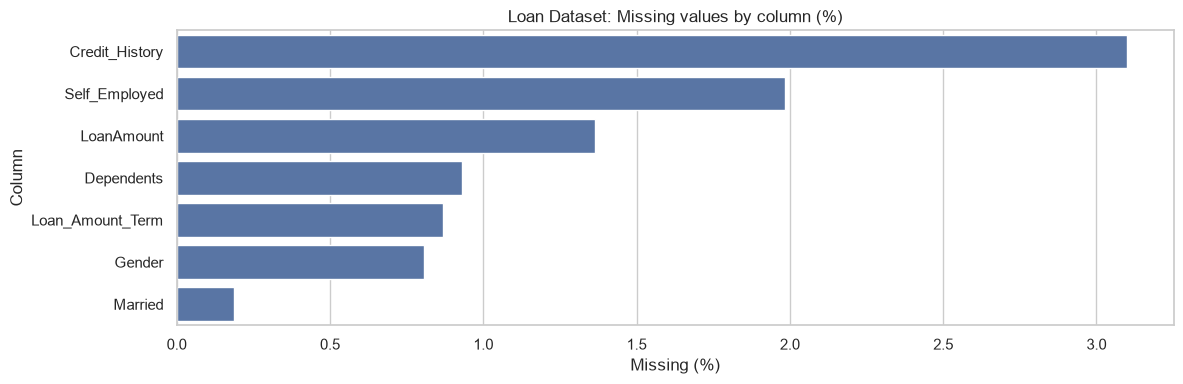

\nLoan Dataset — DISTRIBUTION PLOTS FOR EACH ANALYTICAL COLUMN
Skipped plot for identifier/private field: Loan_ID


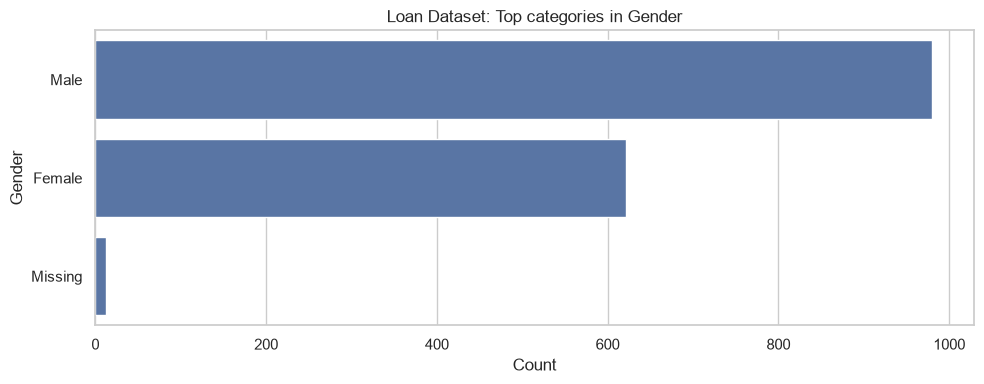

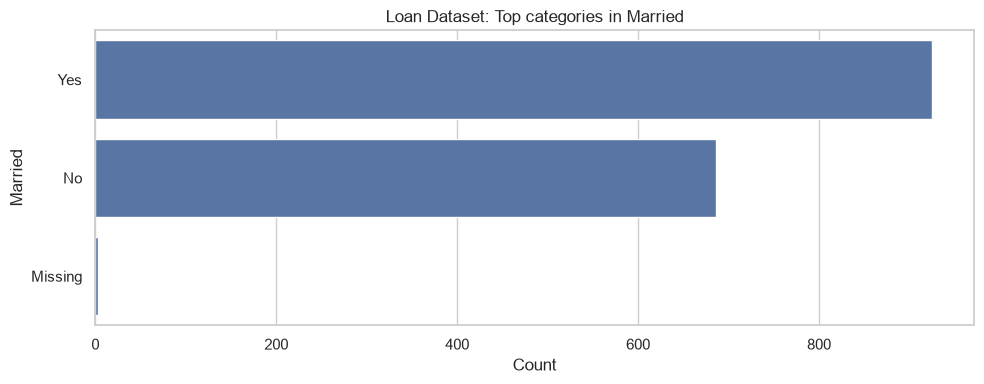

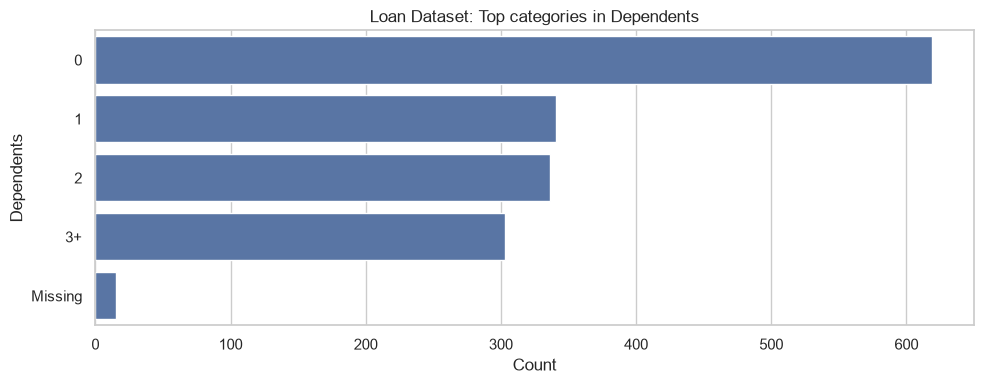

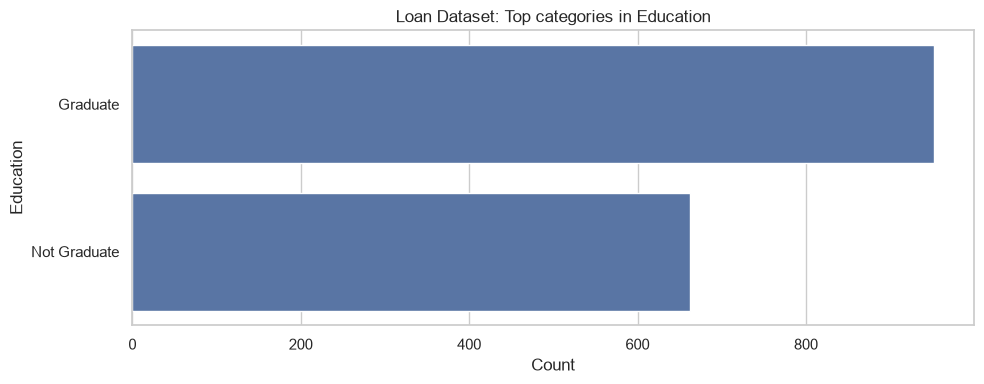

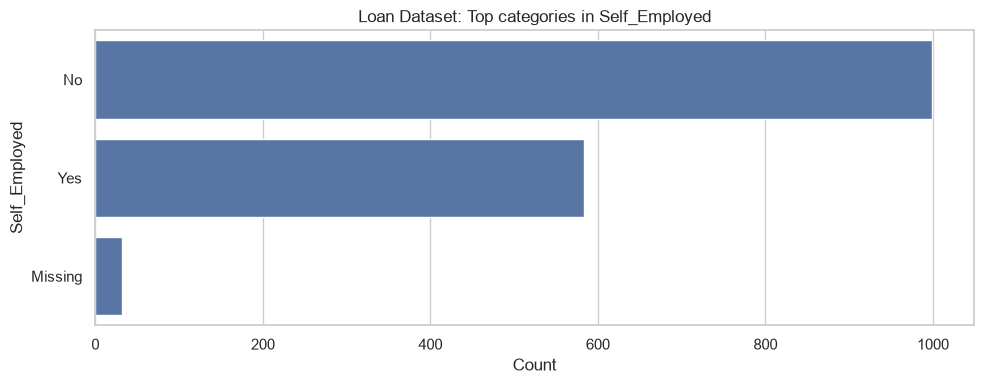

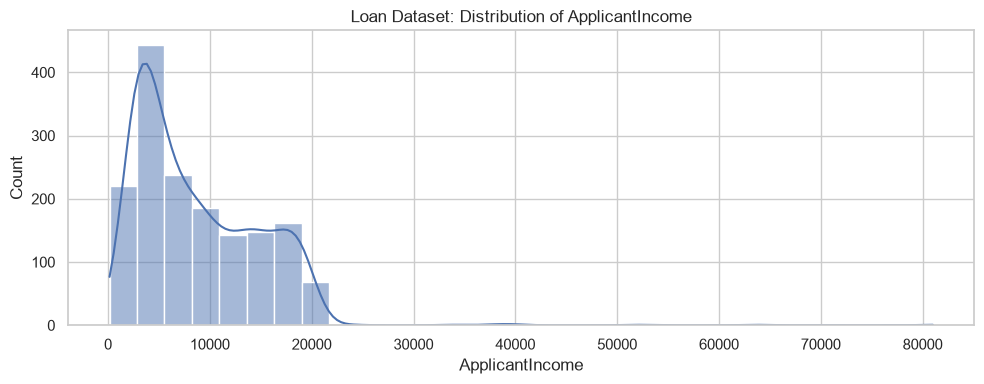

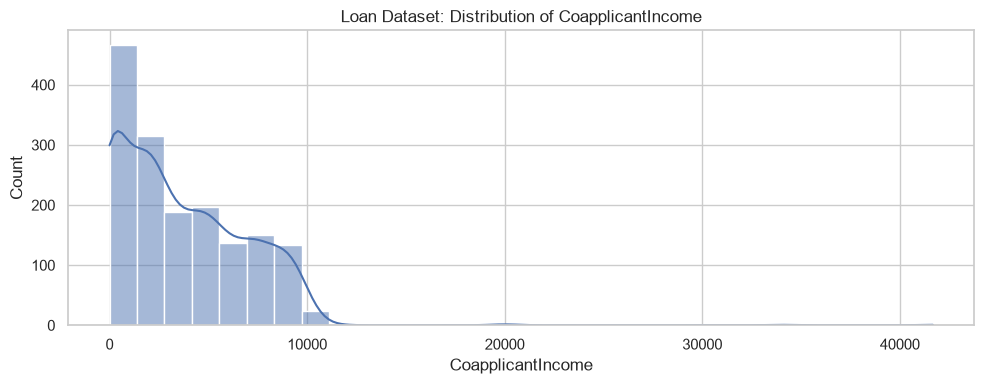

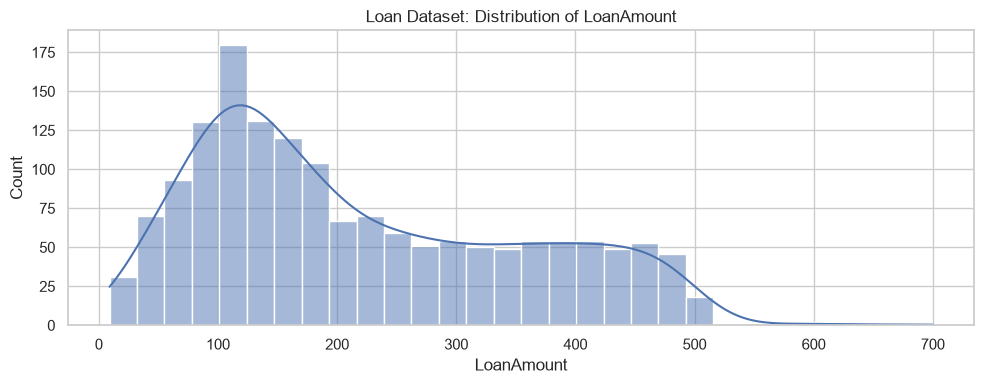

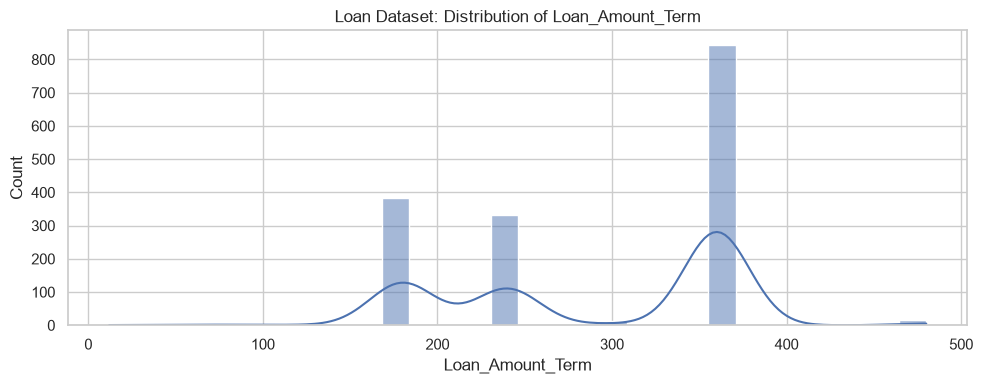

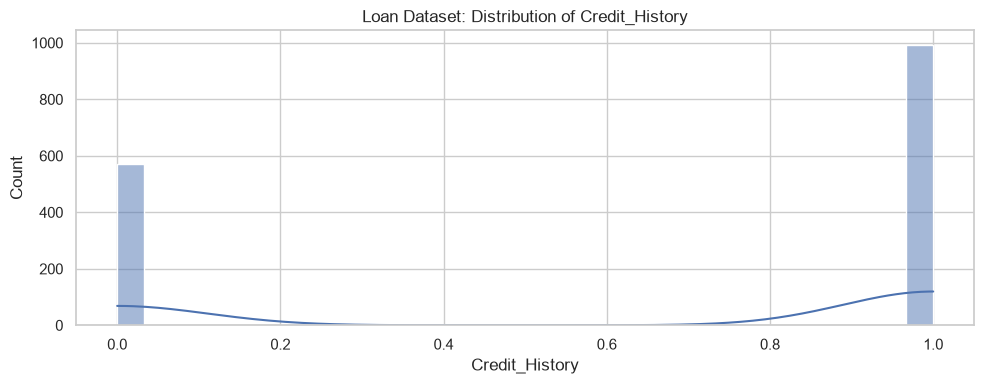

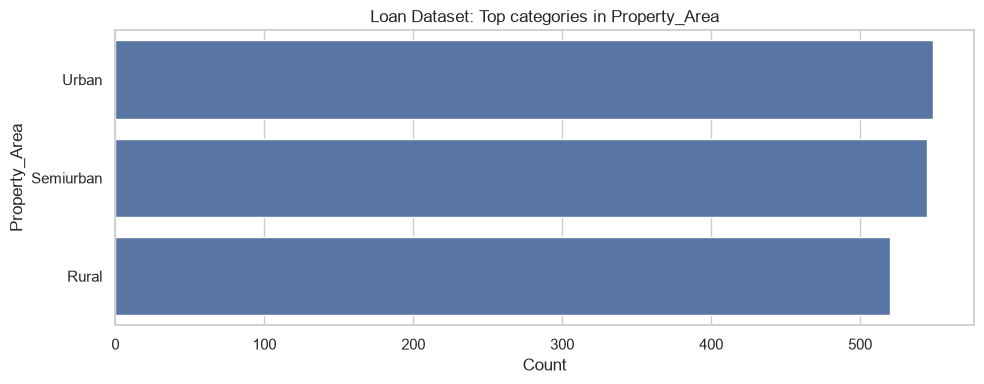

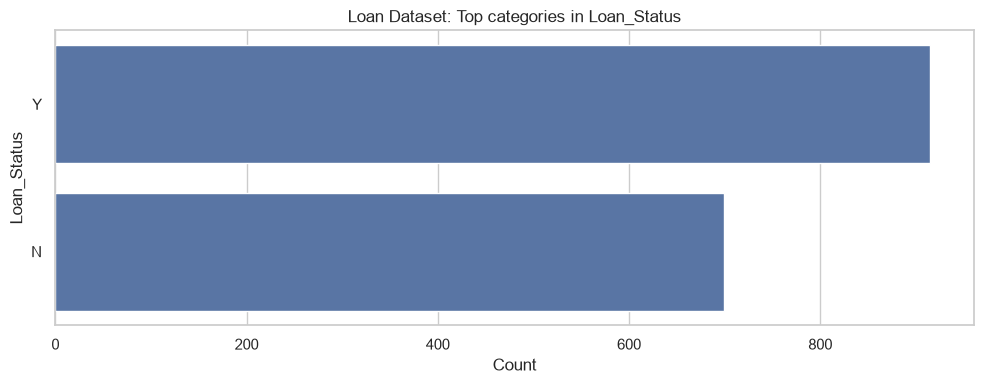

In [9]:
loan = pd.read_csv(LOAN_PATH)
loan_raw = loan.copy()

basic_report(loan, "Loan Dataset")
column_profile(loan, "Loan Dataset")
missing_value_plot(loan, "Loan Dataset")
plot_every_column(loan, "Loan Dataset", exclude_from_plots=["Loan_ID"])


## Loan: Relationships & Outliers
Explore numeric relationships and possible outliers. Do not remove valid values automatically.

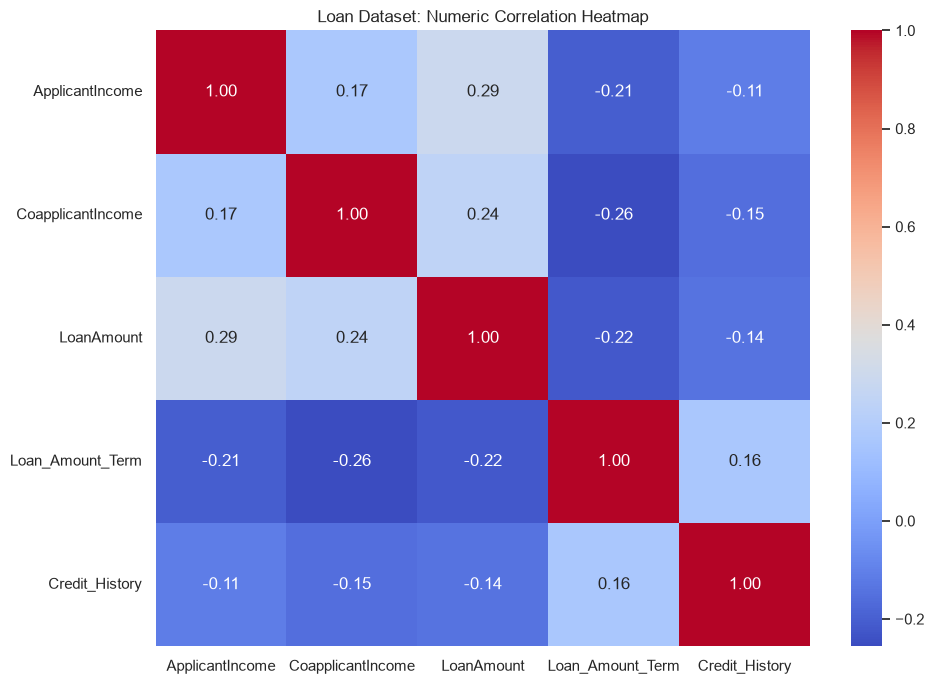

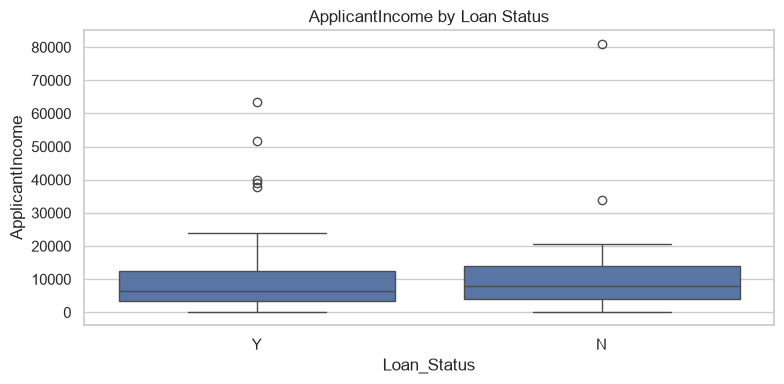

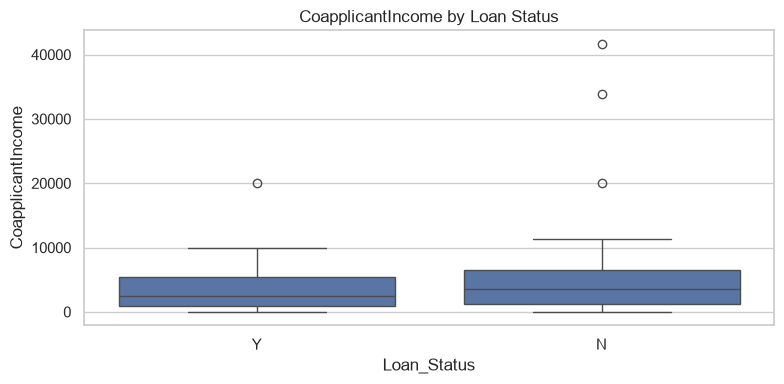

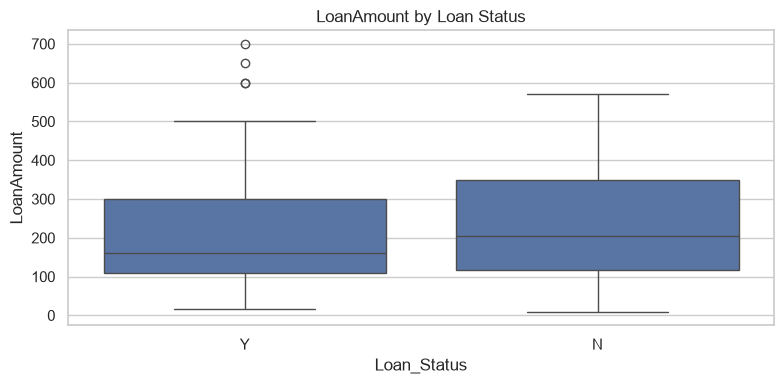

,column,Q1,Q3,IQR_lower_bound,IQR_upper_bound,outlier_count
0,ApplicantIncome,"3,675.25","13,251.00","-10,688.38","27,614.62",7
1,CoapplicantIncome,986.25,"5,893.00","-6,373.88","13,253.12",4
2,LoanAmount,112.00,324.00,-206.00,642.00,2
3,Loan_Amount_Term,240.00,360.00,60.00,540.00,3
4,Credit_History,0.00,1.00,-1.50,2.50,0


In [10]:
loan_num = loan.select_dtypes(include=np.number).columns.tolist()
if len(loan_num) > 1:
    plt.figure(figsize=(10, 7))
    sns.heatmap(loan[loan_num].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Loan Dataset: Numeric Correlation Heatmap")
    plt.tight_layout()
    plt.show()

if "Loan_Status" in loan.columns:
    for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
        if col in loan.columns:
            plt.figure(figsize=(8, 4))
            sns.boxplot(data=loan, x="Loan_Status", y=col)
            plt.title(f"{col} by Loan Status")
            plt.tight_layout()
            plt.show()

display(numeric_outlier_summary(loan))


## Loan: Data Cleaning
Remove duplicates, convert numeric fields, and fill predictor gaps with median/mode. Keep missing targets out of model-ready data.

In [20]:
loan_clean = loan.copy()
loan_clean = loan_clean.drop_duplicates().copy()

if "Dependents" in loan_clean.columns:
    loan_clean["Dependents"] = loan_clean["Dependents"].replace({"3+": "3"})
    loan_clean["Dependents"] = pd.to_numeric(loan_clean["Dependents"], errors="coerce")

for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "Credit_History"]:
    if col in loan_clean.columns:
        loan_clean[col] = pd.to_numeric(loan_clean[col], errors="coerce")

loan_target_missing = int(loan_clean["Loan_Status"].isna().sum()) if "Loan_Status" in loan_clean.columns else 0
loan_model_ready = loan_clean.dropna(subset=["Loan_Status"]).copy() if "Loan_Status" in loan_clean.columns else loan_clean.copy()

loan_predictors = [c for c in loan_model_ready.columns if c not in ["Loan_ID", "Loan_Status"]]
for col in loan_predictors:
    if pd.api.types.is_numeric_dtype(loan_model_ready[col]):
        loan_model_ready[col] = loan_model_ready[col].fillna(loan_model_ready[col].median())
    else:
        modes = loan_model_ready[col].mode(dropna=True)
        if not modes.empty:
            loan_model_ready[col] = loan_model_ready[col].fillna(modes.iloc[0])

print("Missing Loan_Status rows excluded from model-ready copy:", loan_target_missing)
print("Cleaned shape:", loan_model_ready.shape)
display(loan_model_ready.isna().sum().to_frame("remaining_missing"))
display(loan_model_ready.head())


Missing Loan_Status rows excluded from model-ready copy: 0
Cleaned shape: (1614, 13)


,remaining_missing
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.00,Graduate,No,5849,0.00,180.00,360.00,1.00,Urban,Y
1,LP001003,Male,Yes,1.00,Graduate,No,4583,"1,508.00",128.00,360.00,1.00,Rural,N
2,LP001005,Male,Yes,0.00,Graduate,Yes,3000,0.00,66.00,360.00,1.00,Urban,Y
3,LP001006,Male,Yes,0.00,Not Graduate,No,2583,"2,358.00",120.00,360.00,1.00,Urban,Y
4,LP001008,Male,No,0.00,Graduate,No,6000,0.00,141.00,360.00,1.00,Urban,Y


Duplicates after cleaning: 0


,count
Loan_Status,
Y,915
N,699


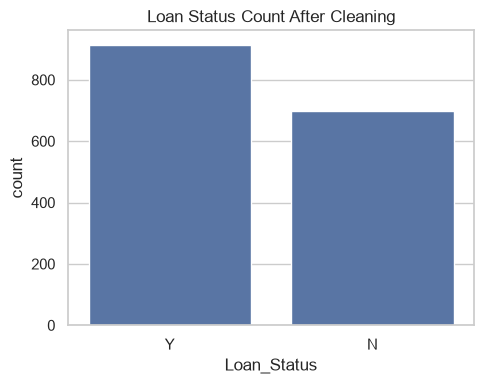

Saved: loan_cleaned.csv


In [25]:
# Post-cleaning verification and target distribution
print("Duplicates after cleaning:", loan_model_ready.duplicated().sum())
if "Loan_Status" in loan_model_ready.columns:
    display(loan_model_ready["Loan_Status"].value_counts(dropna=False).to_frame("count"))
    plt.figure(figsize=(5, 4))
    sns.countplot(data=loan_model_ready, x="Loan_Status")
    plt.title("Loan Status Count After Cleaning")
    plt.tight_layout()
    plt.show()

loan_model_ready.to_csv("loan_cleaned.csv", index=False)
print("Saved: loan_cleaned.csv")


# 2. Adult Census Income
Load and inspect the data. Convert `?` markers to missing values.

In [28]:
adult = pd.read_csv(ADULT_PATH)
adult_raw = adult.copy()

# Standardize whitespace and the dataset's '?' missing-value marker.z
for col in adult.select_dtypes(include="object").columns:
    adult[col] = adult[col].astype("string").str.strip().replace("?", pd.NA)

basic_report(adult, "Adult Census Income Dataset")
column_profile(adult, "Adult Census Income Dataset")
missing_value_plot(adult, "Adult Census Income Dataset")
plot_every_column(adult, "Adult Census Income Dataset")


Adult Census Income Dataset — BASIC INFORMATION
Shape: (48842, 15)
\nData types:


,dtype
age,int64
workclass,string
fnlwgt,int64
education,string
educational-num,int64
marital-status,string
occupation,string
relationship,string
race,string
gender,string


\nFirst five rows:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,<NA>,103497,Some-college,10,Never-married,<NA>,Own-child,White,Female,0,0,30,United-States,<=50K


\nDuplicate rows: 52
\nMissing values by column:


,missing_count,missing_percent
occupation,2809,5.75
workclass,2799,5.73
native-country,857,1.75
fnlwgt,0,0.00
education,0,0.00
educational-num,0,0.00
age,0,0.00
marital-status,0,0.00
relationship,0,0.00
gender,0,0.00


\nNumeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,"48,842.00",38.64,13.71,17.00,28.00,37.00,48.00,90.00
fnlwgt,"48,842.00","189,664.13","105,604.03","12,285.00","117,550.50","178,144.50","237,642.00","1,490,400.00"
educational-num,"48,842.00",10.08,2.57,1.00,9.00,10.00,12.00,16.00
capital-gain,"48,842.00","1,079.07","7,452.02",0.00,0.00,0.00,0.00,"99,999.00"
capital-loss,"48,842.00",87.50,403.00,0.00,0.00,0.00,0.00,"4,356.00"
hours-per-week,"48,842.00",40.42,12.39,1.00,40.00,40.00,45.00,99.00


\nCategorical descriptive statistics:


ValueError: No columns match the specified include or exclude data types

## Adult: Relationships & Outliers
Compare numeric features with income and inspect correlations. Results are descriptive, not causal.

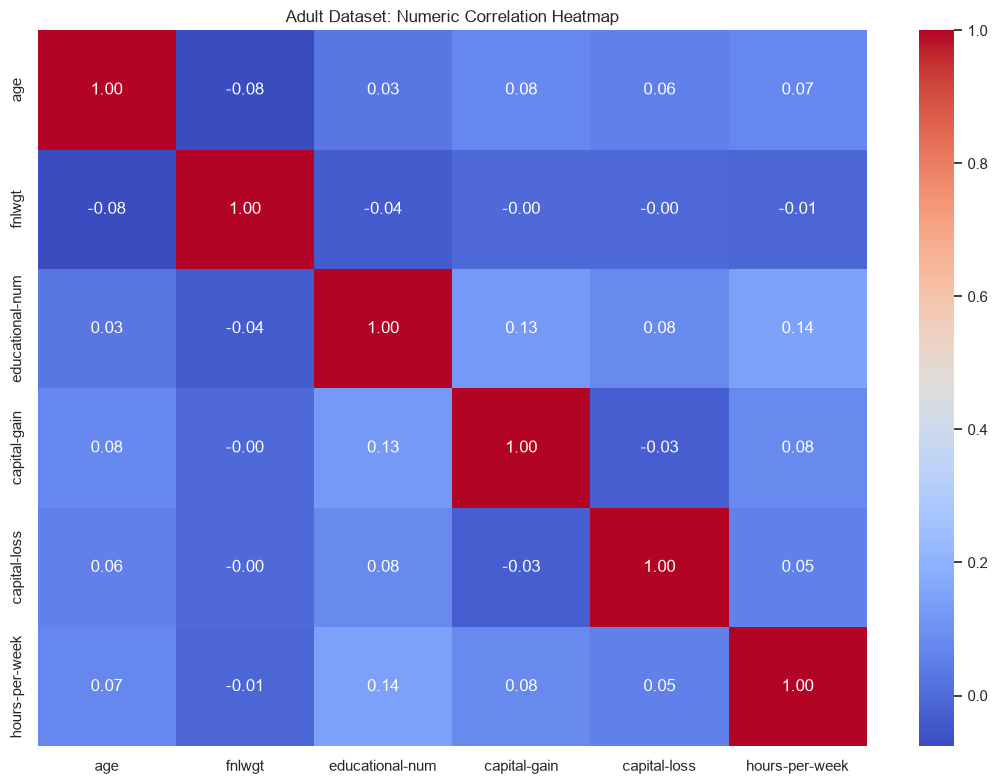

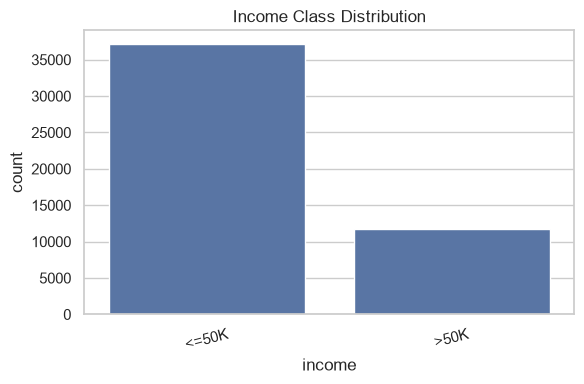

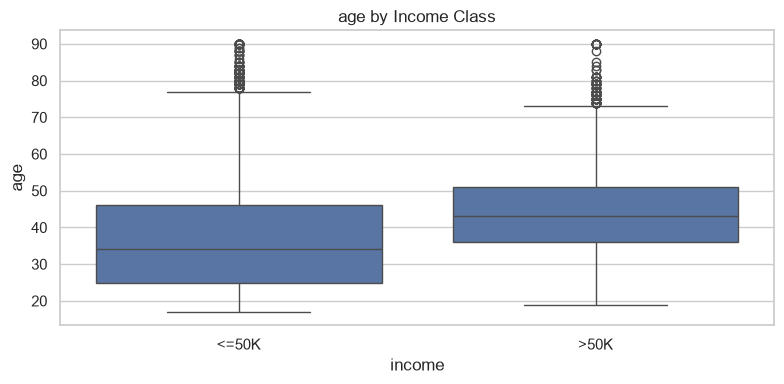

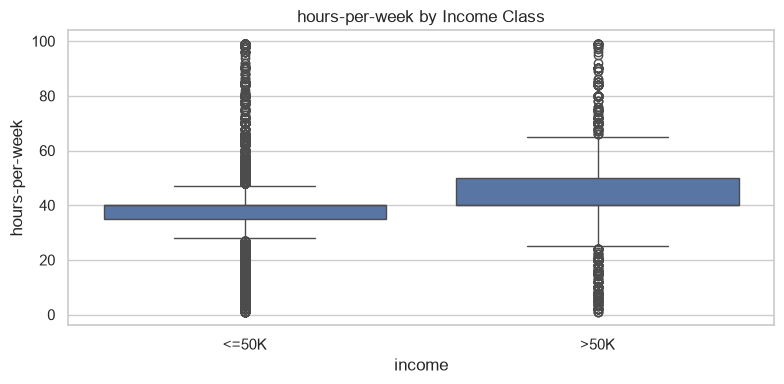

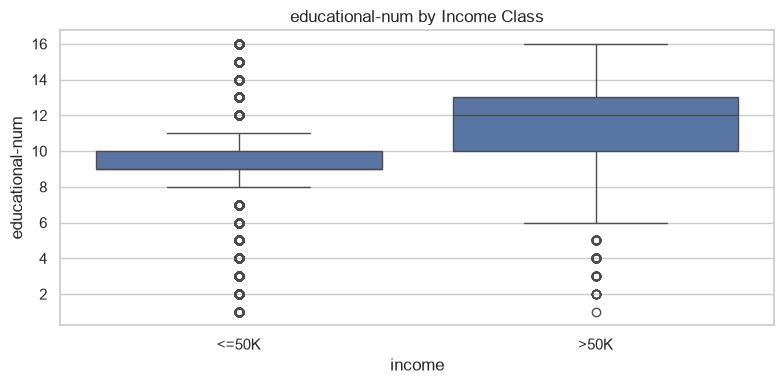

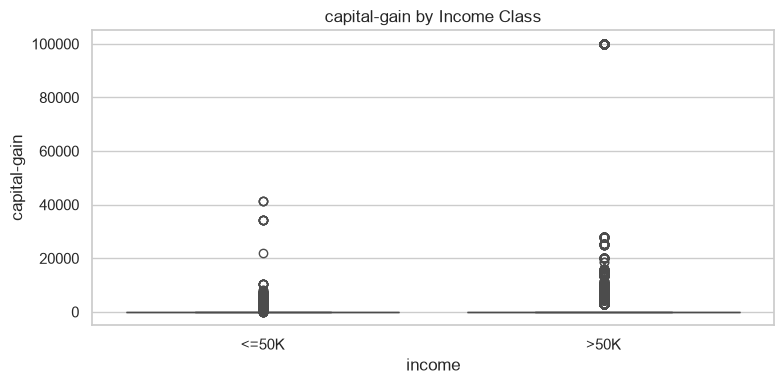

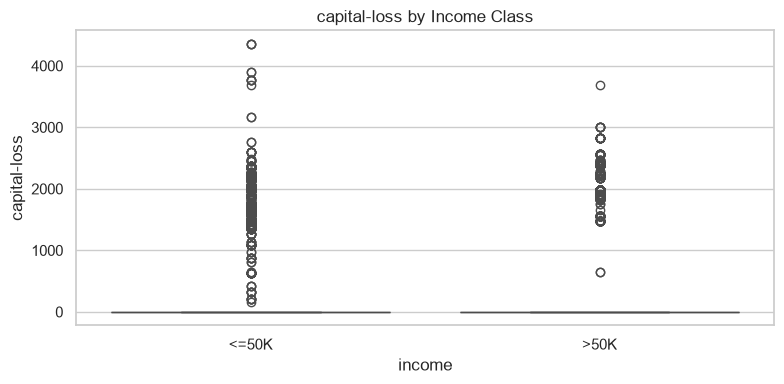

,column,Q1,Q3,IQR_lower_bound,IQR_upper_bound,outlier_count
0,age,28.00,48.00,-2.00,78.00,216
1,fnlwgt,"117,550.50","237,642.00","-62,586.75","417,779.25",1453
2,educational-num,9.00,12.00,4.50,16.50,1794
3,capital-gain,0.00,0.00,0.00,0.00,4035
4,capital-loss,0.00,0.00,0.00,0.00,2282
5,hours-per-week,40.00,45.00,32.50,52.50,13496


In [32]:
adult_numeric = adult.select_dtypes(include=np.number).columns.tolist()
if len(adult_numeric) > 1:
    plt.figure(figsize=(11, 8))
    sns.heatmap(adult[adult_numeric].corr(), cmap="coolwarm", annot=True, fmt=".2f")
    plt.title("Adult Dataset: Numeric Correlation Heatmap")
    plt.tight_layout()
    plt.show()

if "income" in adult.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=adult, x="income")
    plt.title("Income Class Distribution")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()
    for col in ["age", "hours-per-week", "educational-num", "capital-gain", "capital-loss"]:
        if col in adult.columns:
            plt.figure(figsize=(8, 4))
            sns.boxplot(data=adult, x="income", y=col)
            plt.title(f"{col} by Income Class")
            plt.tight_layout()
            plt.show()

display(numeric_outlier_summary(adult))


## Adult: Data Cleaning
Remove duplicates, impute missing predictors, and exclude rows with missing income labels. Report outliers without automatically deleting them.

In [38]:
adult_clean = adult.copy().drop_duplicates()

adult_target_missing = int(adult_clean["income"].isna().sum()) if "income" in adult_clean.columns else 0
adult_model_ready = adult_clean.dropna(subset=["income"]).copy() if "income" in adult_clean.columns else adult_clean.copy()

for col in adult_model_ready.columns:
    if pd.api.types.is_numeric_dtype(adult_model_ready[col]):
        median_value = adult_model_ready[col].median()
        adult_model_ready[col] = adult_model_ready[col].fillna(median_value)
    else:
        modes = adult_model_ready[col].mode(dropna=True)
        if not modes.empty:
            adult_model_ready[col] = adult_model_ready[col].fillna(modes.iloc[0])

print("Rows excluded due to missing income target:", adult_target_missing)
print("Cleaned shape:", adult_model_ready.shape)
display(adult_model_ready.isna().sum().to_frame("remaining_missing"))
display(adult_model_ready.head())


Rows excluded due to missing income target: 0
Cleaned shape: (48790, 15)


,remaining_missing
age,0
workclass,0
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,0
relationship,0
race,0
gender,0


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,103497,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,30,United-States,<=50K


In [46]:
# Post-cleaning verification and selected categorical comparisons
print("Duplicates after cleaning:", adult_model_ready.duplicated().sum())
display(adult_model_ready["income"].value_counts().to_frame("count"))

for col in ["education", "workclass", "gender", "marital-status"]:
    if col in adult_model_ready.columns:
        ct = pd.crosstab(adult_model_ready[col], adult_model_ready["income"], normalize="index") * 100
        display(ct.round(1).head(20))

adult_model_ready.to_csv("adult_cleaned.csv", index=False)
print("Saved: adult_cleaned.csv")


Duplicates after cleaning: 1


,count
income,
<=50K,37109
>50K,11681


income,<=50K,>50K
education,,
10th,93.70,6.30
11th,94.90,5.10
12th,92.70,7.30
1st-4th,96.70,3.30
5th-6th,94.70,5.30
7th-8th,93.50,6.50
9th,94.60,5.40
Assoc-acdm,74.20,25.80
Assoc-voc,74.70,25.30


income,<=50K,>50K
workclass,,
Federal-gov,60.80,39.20
Local-gov,70.40,29.60
Never-worked,100.00,0.00
Private,79.10,20.90
Self-emp-inc,44.60,55.40
Self-emp-not-inc,72.10,27.90
State-gov,73.20,26.80
Without-pay,90.50,9.50


income,<=50K,>50K
gender,,
Female,89.10,10.90
Male,69.60,30.40


income,<=50K,>50K
marital-status,,
Divorced,89.90,10.10
Married-AF-spouse,62.20,37.80
Married-civ-spouse,55.40,44.60
Married-spouse-absent,90.70,9.30
Never-married,95.40,4.60
Separated,93.50,6.50
Widowed,91.60,8.40


Saved: adult_cleaned.csv


# 3. Hotel Booking
Load and inspect bookings. Exclude personal identifiers from analytical outputs.

In [51]:
hotel = pd.read_csv(HOTEL_PATH)
hotel_raw = hotel.copy()

# Normalize object whitespace without altering the underlying category meaning.
for col in hotel.select_dtypes(include="object").columns:
    hotel[col] = hotel[col].astype("string").str.strip()

basic_report(hotel, "Hotel Booking Dataset")
column_profile(hotel, "Hotel Booking Dataset")
missing_value_plot(hotel, "Hotel Booking Dataset")

private_columns = [c for c in ["name", "email", "phone-number", "credit_card"] if c in hotel.columns]
print("Personal identifier columns excluded from analytical plots:", private_columns)
plot_every_column(hotel, "Hotel Booking Dataset", exclude_from_plots=private_columns)


Hotel Booking Dataset — BASIC INFORMATION
Shape: (119390, 36)
\nData types:


,dtype
hotel,string
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,string
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


\nFirst five rows:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


\nDuplicate rows: 0
\nMissing values by column:


,missing_count,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
hotel,0,0.00
arrival_date_year,0,0.00
lead_time,0,0.00
is_canceled,0,0.00
arrival_date_month,0,0.00
stays_in_week_nights,0,0.00
adults,0,0.00


\nNumeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
is_canceled,"119,390.00",0.37,0.48,0.00,0.00,0.00,1.00,1.00
lead_time,"119,390.00",104.01,106.86,0.00,18.00,69.00,160.00,737.00
arrival_date_year,"119,390.00","2,016.16",0.71,"2,015.00","2,016.00","2,016.00","2,017.00","2,017.00"
arrival_date_week_number,"119,390.00",27.17,13.61,1.00,16.00,28.00,38.00,53.00
arrival_date_day_of_month,"119,390.00",15.80,8.78,1.00,8.00,16.00,23.00,31.00
stays_in_weekend_nights,"119,390.00",0.93,1.00,0.00,0.00,1.00,2.00,19.00
stays_in_week_nights,"119,390.00",2.50,1.91,0.00,1.00,2.00,3.00,50.00
adults,"119,390.00",1.86,0.58,0.00,2.00,2.00,2.00,55.00
children,"119,386.00",0.10,0.40,0.00,0.00,0.00,0.00,10.00
babies,"119,390.00",0.01,0.10,0.00,0.00,0.00,0.00,10.00


\nCategorical descriptive statistics:


ValueError: No columns match the specified include or exclude data types

## Hotel: Booking Analysis
Explore cancellations, booking categories, numeric distributions, and correlations.

,cancellation_rate_percent
hotel,
City Hotel,41.73
Resort Hotel,27.76


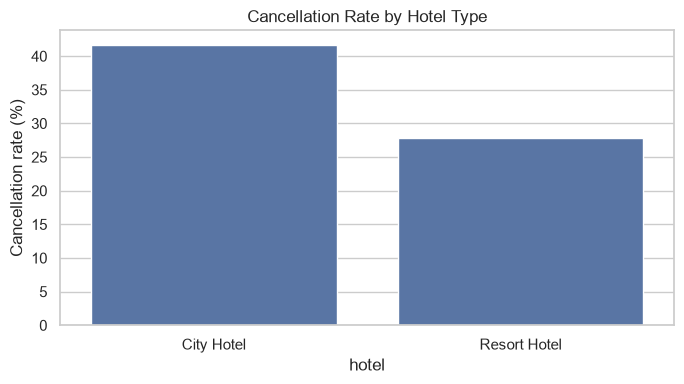

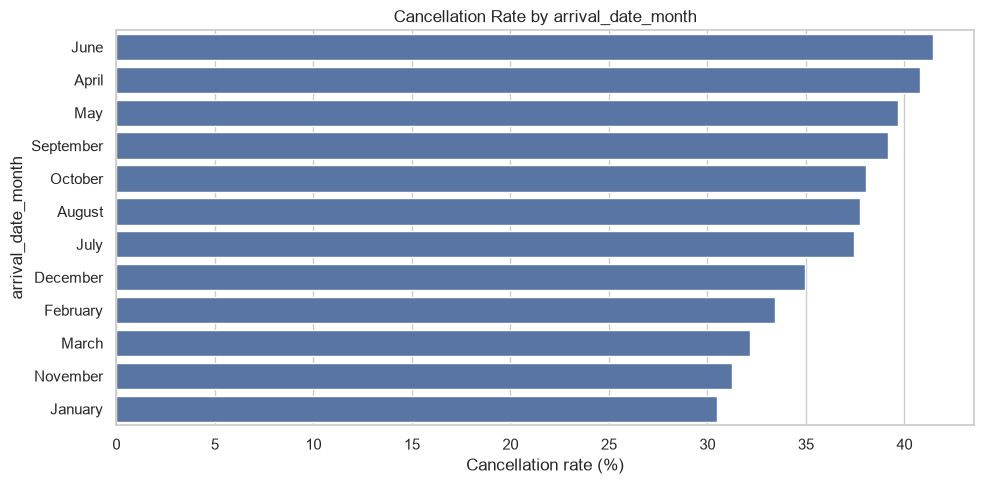

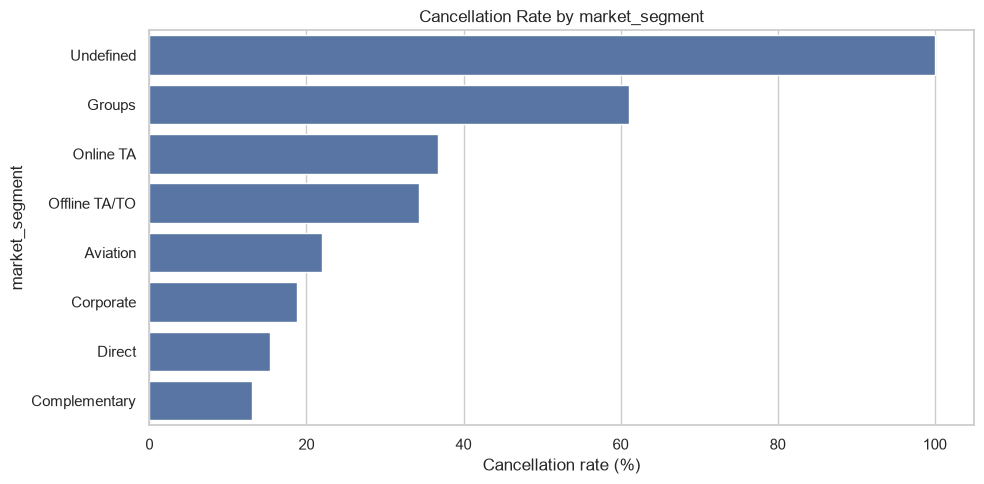

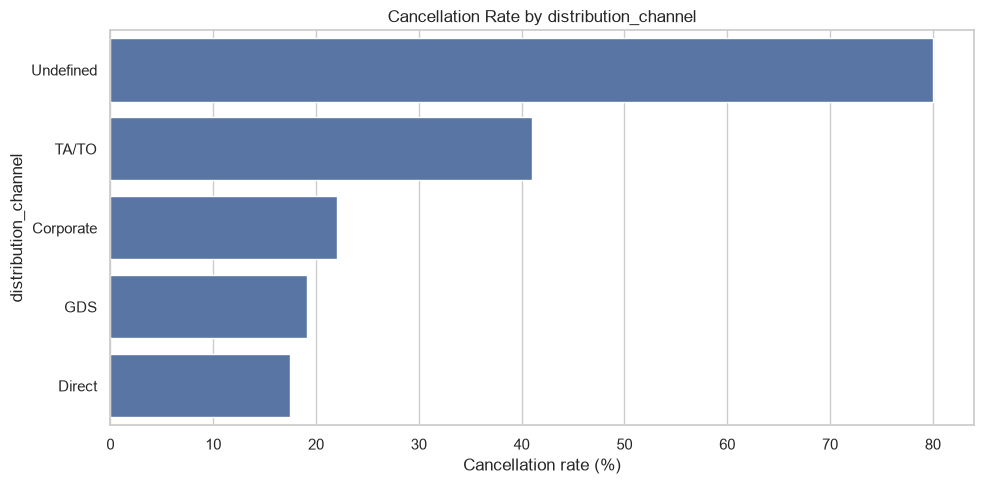

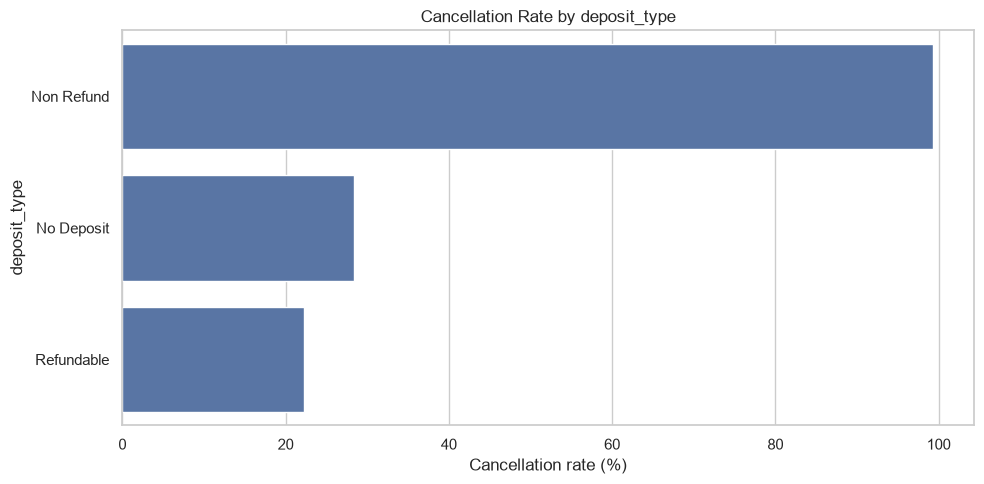

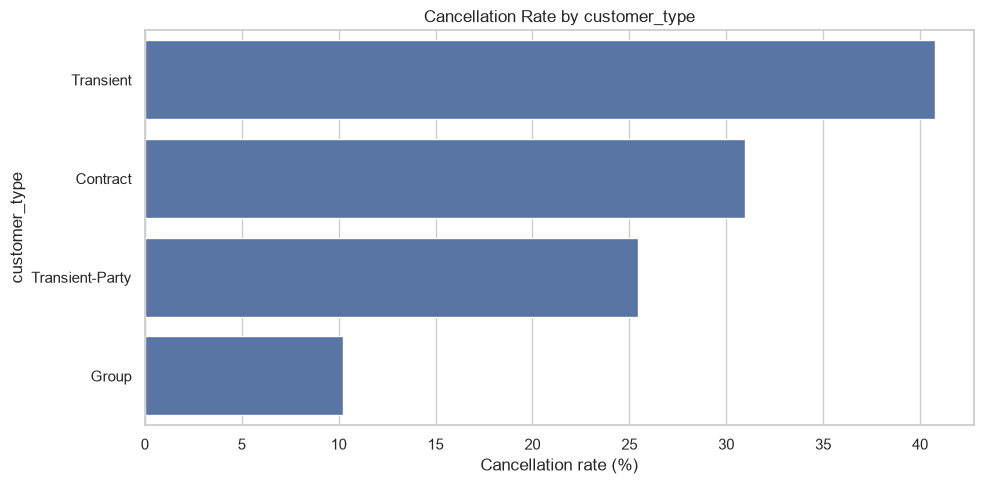

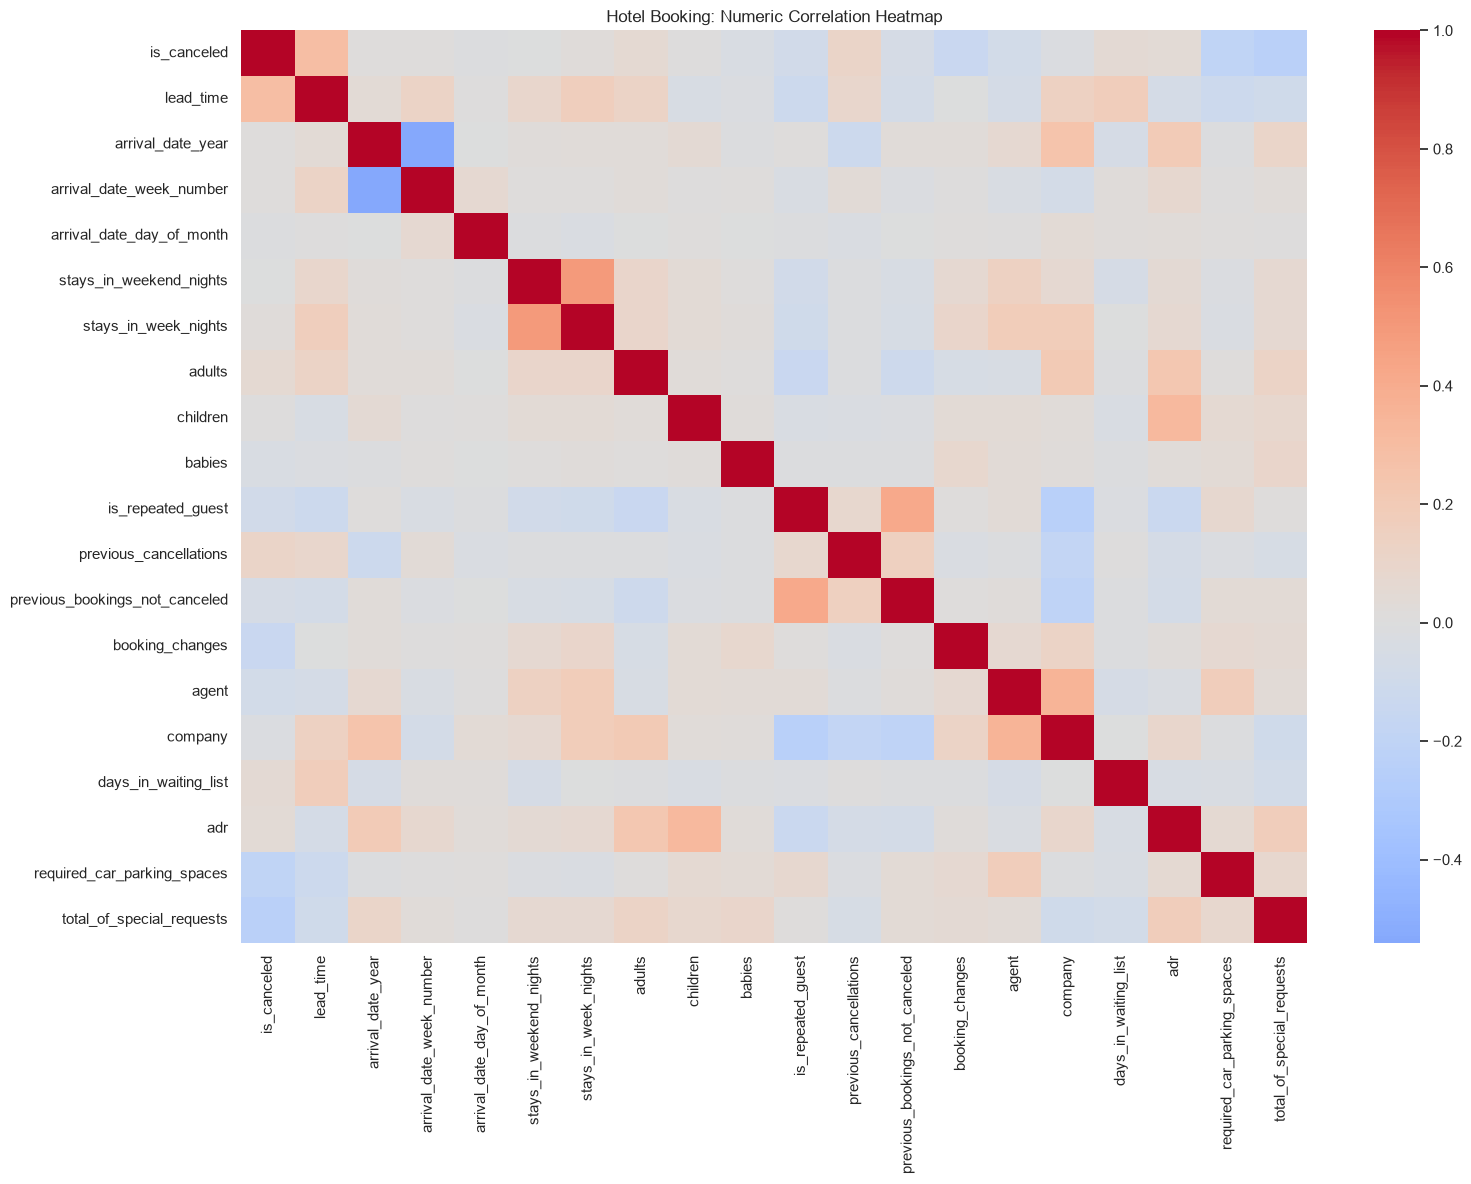

,column,Q1,Q3,IQR_lower_bound,IQR_upper_bound,outlier_count
0,is_canceled,0.00,1.00,-1.50,2.50,0
1,lead_time,18.00,160.00,-195.00,373.00,3005
2,arrival_date_year,"2,016.00","2,017.00","2,014.50","2,018.50",0
3,arrival_date_week_number,16.00,38.00,-17.00,71.00,0
4,arrival_date_day_of_month,8.00,23.00,-14.50,45.50,0
5,stays_in_weekend_nights,0.00,2.00,-3.00,5.00,265
6,stays_in_week_nights,1.00,3.00,-2.00,6.00,3354
7,adults,2.00,2.00,2.00,2.00,29710
8,children,0.00,0.00,0.00,0.00,8590
9,babies,0.00,0.00,0.00,0.00,917


In [60]:
# Cancellation rate by hotel
if {"hotel", "is_canceled"}.issubset(hotel.columns):
    cancel_rate = hotel.groupby("hotel")["is_canceled"].mean().mul(100).sort_values(ascending=False)
    display(cancel_rate.to_frame("cancellation_rate_percent"))
    plt.figure(figsize=(7, 4))
    sns.barplot(x=cancel_rate.index, y=cancel_rate.values)
    plt.ylabel("Cancellation rate (%)")
    plt.title("Cancellation Rate by Hotel Type")
    plt.tight_layout()
    plt.show()

# Cancellation by selected categorical fields
for col in ["arrival_date_month", "market_segment", "distribution_channel", "deposit_type", "customer_type"]:
    if {col, "is_canceled"}.issubset(hotel.columns):
        rates = hotel.groupby(col, dropna=False)["is_canceled"].mean().mul(100).sort_values(ascending=False).head(20)
        plt.figure(figsize=(10, 5))
        sns.barplot(x=rates.values, y=rates.index.astype(str))
        plt.xlabel("Cancellation rate (%)")
        plt.title(f"Cancellation Rate by {col}")
        plt.tight_layout()
        plt.show()

hotel_numeric = hotel.select_dtypes(include=np.number).columns.tolist()
# Exclude high-cardinality/identifier-like numeric fields from the heatmap only if needed.
if len(hotel_numeric) > 1:
    corr = hotel[hotel_numeric].corr()
    plt.figure(figsize=(16, 12))
    sns.heatmap(corr, cmap="coolwarm", center=0)
    plt.title("Hotel Booking: Numeric Correlation Heatmap")
    plt.tight_layout()
    plt.show()

display(numeric_outlier_summary(hotel))


## Hotel: Data Cleaning
Remove duplicates, fix data types, handle missing values, and remove impossible negative counts/stays. Retain optional agent/company IDs as missing; review outliers before acting.

In [63]:
hotel_clean = hotel.copy().drop_duplicates()

if "reservation_status_date" in hotel_clean.columns:
    hotel_clean["reservation_status_date"] = pd.to_datetime(
        hotel_clean["reservation_status_date"], errors="coerce"
    )

for col in ["children", "agent", "company", "adr"]:
    if col in hotel_clean.columns:
        hotel_clean[col] = pd.to_numeric(hotel_clean[col], errors="coerce")

# Validate logically non-negative count/duration columns.
numeric_cols = [
    "lead_time", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults", "children",
    "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "required_car_parking_spaces",
    "total_of_special_requests", "agent", "company", "adr"
]

for col in numeric_cols:
    if col in hotel_clean.columns:
        hotel_clean[col] = pd.to_numeric(
            hotel_clean[col], errors="coerce"
        )

# Missing numeric guest count is filled with median; keep optional agent/company IDs missing.
for col in ["children"]:
    if col in hotel_clean.columns:
        hotel_clean[col] = hotel_clean[col].fillna(hotel_clean[col].median())

# ADR is a monetary rate; retain missing values if no defensible replacement exists.
# Remove personal identifiers from analytical dataset.
hotel_analytical = hotel_clean.drop(columns=private_columns, errors="ignore").copy()

print("Cleaned analytical shape:", hotel_analytical.shape)
display(hotel_analytical.isna().sum().sort_values(ascending=False).to_frame("remaining_missing").head(20))
display(hotel_analytical.head())


NameError: name 'private_columns' is not defined

In [ ]:
# Post-cleaning verification and useful derived columns
print("Duplicates after cleaning:", hotel_analytical.duplicated().sum())

if {"stays_in_weekend_nights", "stays_in_week_nights"}.issubset(hotel_analytical.columns):
    hotel_analytical["total_nights"] = (
        hotel_analytical["stays_in_weekend_nights"] +
        hotel_analytical["stays_in_week_nights"]
    )

if {"adults", "children", "babies"}.issubset(hotel_analytical.columns):
    hotel_analytical["total_guests"] = (
        hotel_analytical["adults"] +
        hotel_analytical["children"] +
        hotel_analytical["babies"]
    )

if "reservation_status_date" in hotel_analytical.columns:
    hotel_analytical["reservation_status_year"] = hotel_analytical["reservation_status_date"].dt.year
    hotel_analytical["reservation_status_month"] = hotel_analytical["reservation_status_date"].dt.month

if "is_canceled" in hotel_analytical.columns:
    display(hotel_analytical["is_canceled"].value_counts(normalize=True).mul(100).round(2).to_frame("percent"))

hotel_analytical.to_csv("hotel_booking_cleaned.csv", index=False)
print("Saved: hotel_booking_cleaned.csv")


# Final Comparison
Compare original and cleaned datasets. Add 3–5 findings per dataset covering missing values, duplicates, patterns, relationships, and cleaning decisions.

In [ ]:
summary = pd.DataFrame([
    {
        "dataset": "Loan",
        "original_rows": len(loan_raw), "cleaned_rows": len(loan_model_ready),
        "original_columns": loan_raw.shape[1], "cleaned_columns": loan_model_ready.shape[1],
        "remaining_missing_cells": int(loan_model_ready.isna().sum().sum())
    },
    {
        "dataset": "Adult",
        "original_rows": len(adult_raw), "cleaned_rows": len(adult_model_ready),
        "original_columns": adult_raw.shape[1], "cleaned_columns": adult_model_ready.shape[1],
        "remaining_missing_cells": int(adult_model_ready.isna().sum().sum())
    },
    {
        "dataset": "Hotel Booking",
        "original_rows": len(hotel_raw), "cleaned_rows": len(hotel_analytical),
        "original_columns": hotel_raw.shape[1], "cleaned_columns": hotel_analytical.shape[1],
        "remaining_missing_cells": int(hotel_analytical.isna().sum().sum())
    }
])
display(summary)
print("Output files: loan_cleaned.csv, adult_cleaned.csv, hotel_booking_cleaned.csv")
